# 01 · Prototyp detektora na danych syntetycznych (T09)

Cel: wybrać metodę detekcji i regułę progu, zanim powstaną prawdziwe dane z klastra (T20).

Notebook:
1. generuje syntetyczne szeregi 9 cech z tabeli reguł nagrywających (`docs/architektura.md`) dla `frontend` i `orders`, krok 30 s;
2. wstrzykuje anomalie odpowiadające scenariuszom S1–S7;
3. porównuje trzy detektory: **IsolationForest**, **kroczący z-score** (maksymalne |z| po cechach) i **stałe progi** (alerty regułowe);
4. liczy precision, recall, F1, opóźnienie wykrycia i fałszywe alarmy na godzinę.

Definicje ewaluacji są te same co w T30, żeby wyniki prototypu dało się porównać z przebiegami na klastrze:
- alert = flaga anomalii utrzymana przez `for` reguły (`AnomalyDetected`: 1 min, ewaluacja co 30 s);
- **wykrycie** = początek alertu usługi docelowej w przedziale [start, end + 5 min], **opóźnienie** = początek alertu − start;
- **fałszywy alarm** = początek alertu (dowolnej usługi) poza wszystkimi oknami [start − 1 min, end + 5 min];
- recall = wykryte scenariusze / 7, precision = alerty w oknach / wszystkie alerty.

Wszystko jest deterministyczne (stałe ziarna), więc wynik nie zależy od uruchomienia.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 3)
# Niska rozdzielczość wykresów: notebook z wynikami jest w git.
plt.rcParams["figure.dpi"] = 60

STEPS_PER_MIN = 2  # krok reguł nagrywających: 30 s
TRAIN_MINUTES = 30  # TRAIN_WINDOW z T23
TRAIN_STEPS = TRAIN_MINUTES * STEPS_PER_MIN
GAP_STEPS = 10 * STEPS_PER_MIN  # domyślne --gap z T21
GRACE_BEFORE = 1 * STEPS_PER_MIN
GRACE_AFTER = 5 * STEPS_PER_MIN
SEEDS = range(20)  # 20 przebiegów S1–S7

SERVICES = ("frontend", "orders")
FEATURES = [
    "cpu_usage_ratio_of_limit",
    "memory_working_set_ratio_of_limit",
    "network_rx_bytes_rate1m",
    "network_tx_bytes_rate1m",
    "http_requests_rate1m",
    "http_errors_ratio_rate1m",
    "http_latency_p95_seconds_1m",
    "restarts_increase5m",
    "policy_drops_rate1m",
]


@dataclass(frozen=True)
class Scenario:
    id: str
    name: str
    target: str
    minutes: int

    @property
    def steps(self) -> int:
        return self.minutes * STEPS_PER_MIN


SCENARIOS = [
    Scenario("S1", "cpu", "orders", 2),
    Scenario("S2", "memory", "orders", 3),
    Scenario("S3", "errors", "orders", 3),
    Scenario("S4", "latency", "orders", 3),
    Scenario("S5", "crash", "orders", 3),
    Scenario("S6", "spike", "frontend", 3),
    Scenario("S7", "scan", "orders", 2),
]

## Model danych

Założenia, z których wynikają szeregi (każde da się sprawdzić na klastrze po T16/T18):

- **Ruch bazowy (T18):** Locust, 10 ± 8 użytkowników, sinusoida o okresie 30 min + szum, ok. 1 żądanie/s na użytkownika; 70% `GET /`, 30% `POST /order`, więc `orders` dostaje 0,3 ruchu `frontend`.
- **Okno treningowe** to 30 min = jeden okres sinusoidy: model widzi cały zakres normalnego ruchu.
- **Poziomy bazowe** z pomiarów T05/T08: `orders` zajmuje ok. 40 MB z limitu 256 Mi (0,16), CPU rośnie liniowo z ruchem, błędy są rzadkie (pojedyncze 5xx), restartów i odrzuceń polityk nie ma.
- **Funkcje `rate1m`/`p95_1m`** wygładzają sygnał na 2 kroki, `restarts:increase5m` sumuje restarty z 10 kroków.

Skutki scenariuszy (na podstawie smoke testów T08 i kontraktu):

| ID | Cel | Skutek w cechach |
|---|---|---|
| S1 cpu | orders | CPU ≈ 0,97 limitu (throttling przy 500m), p95 +40 ms w obu usługach (GIL) |
| S2 memory | orders | pamięć 0,6 → 0,9 limitu |
| S3 errors | orders | 50% błędów w orders, 15% (502) we frontend |
| S4 latency | orders | p95 ≈ 0,5 s w orders i we frontend (30% żądań czeka na orders) |
| S5 crash | orders | 3 restarty co 60 s: `restarts` 1→3, chwilowy spadek ruchu, skok CPU przy starcie, świeży proces ma mniej pamięci, 502 we frontend |
| S6 spike | frontend | +50 użytkowników: ruch, CPU i sieć obu usług w górę |
| S7 scan | orders | tylko `policy_drops` ≈ 6/s (pakiety intrudera nie docierają do aplikacji) |

In [2]:
def _rate1m(values: np.ndarray) -> np.ndarray:
    return pd.Series(values).rolling(2, min_periods=1).mean().to_numpy()


def _error_ratio(
    rng: np.random.Generator, rps: np.ndarray, p: np.ndarray
) -> np.ndarray:
    requests = np.maximum(np.round(rps * 30), 1).astype(int)
    return rng.binomial(requests, np.clip(p, 0, 1)) / requests


def simulate(
    seed: int,
    scenarios: tuple[Scenario, ...] = tuple(SCENARIOS),
    extra_minutes: int = 0,
    memory_drift_per_hour: float = 0.0,
    noise: float = 1.0,
    glitch_rate: float = 0.0,
) -> tuple[dict[str, pd.DataFrame], pd.DataFrame]:
    """Jeden przebieg: 30 min treningu, potem scenariusze w losowej kolejności co 10 min."""
    rng = np.random.default_rng(seed)
    order = [scenarios[i] for i in rng.permutation(len(scenarios))]
    n = (
        TRAIN_STEPS
        + sum(GAP_STEPS + s.steps for s in order)
        + GAP_STEPS
        + extra_minutes * STEPS_PER_MIN
    )

    labels = []
    active = np.full(n, "", dtype=object)
    position = TRAIN_STEPS
    for scenario in order:
        position += GAP_STEPS
        start, end = position, position + scenario.steps
        active[start:end] = scenario.name
        labels.append(
            {
                "scenario": scenario.id,
                "name": scenario.name,
                "target": scenario.target,
                "start": start,
                "end": end,
            }
        )
        position = end
    labels_df = pd.DataFrame(
        labels, columns=["scenario", "name", "target", "start", "end"]
    )

    def window(name: str) -> np.ndarray:
        return active == name

    def window_progress(name: str) -> np.ndarray:
        # Numer kroku od początku okna scenariusza (−1 poza oknem).
        progress = np.full(n, -1)
        for row in labels_df[labels_df.name == name].itertuples():
            progress[row.start : row.end] = np.arange(row.end - row.start)
        return progress

    t = np.arange(n) * 30.0
    phase = rng.uniform(0, 2 * np.pi)
    users = np.clip(
        10 + 8 * np.sin(2 * np.pi * t / 1800 + phase) + rng.normal(0, 1.0 * noise, n),
        1,
        None,
    )
    users = users + 50 * window("spike")
    front_rps = users * (1 + rng.normal(0, 0.05 * noise, n))

    crash_progress = window_progress("crash")
    crash = np.isin(crash_progress, [0, 2, 4])  # 3 restarty co 60 s
    since_crash = np.full(n, 99)
    last = -99
    for i in range(n):
        last = i if crash[i] else last
        since_crash[i] = i - last
    unavailable = np.where(
        crash, 5 / 30, 0.0
    )  # ok. 5 s bez orders przy każdym restarcie

    orders_rps = (
        0.3 * front_rps * (1 + rng.normal(0, 0.08 * noise, n)) * (1 - unavailable)
    )
    # Pojedyncze zakłócenia ruchu normalnego (GC, zimna ścieżka, chwilowy błąd), osobno dla usług.
    o_glitch = rng.random(n) < glitch_rate
    f_glitch = rng.random(n) < glitch_rate

    # orders
    o_cpu = (
        0.03
        + 0.01 * orders_rps
        + rng.normal(0, 0.005 * noise, n)
        + 0.15 * crash
        + 0.1 * o_glitch
    )
    o_cpu = np.where(window("cpu"), 0.97 + rng.normal(0, 0.01, n), o_cpu)
    o_mem = 0.16 + 0.0005 * orders_rps + rng.normal(0, 0.003 * noise, n)
    o_mem -= np.where(since_crash < 4, 0.03 * (4 - since_crash) / 4, 0)
    o_mem += (
        np.clip(np.arange(n) - TRAIN_STEPS, 0, None)
        / (60 * STEPS_PER_MIN)
        * memory_drift_per_hour
    )
    memory_progress = window_progress("memory")
    o_mem = np.where(
        memory_progress == 0,
        0.6,
        np.where(memory_progress > 0, 0.9 + rng.normal(0, 0.005, n), o_mem),
    )
    o_err = _error_ratio(
        rng, orders_rps, np.where(window("errors"), 0.5, 0.001 + 0.03 * o_glitch)
    )
    o_p95 = (
        0.012
        + 0.0004 * orders_rps
        + np.abs(rng.normal(0, 0.002 * noise, n))
        + 0.04 * window("cpu")
        + 0.15 * o_glitch
    )
    o_p95 = np.where(window("latency"), 0.5 + np.abs(rng.normal(0, 0.01, n)), o_p95)
    o_drops = np.where(window("scan"), np.clip(rng.normal(6, 0.5, n), 0, None), 0.0)

    # frontend
    f_cpu = 0.04 + 0.009 * front_rps + rng.normal(0, 0.008 * noise, n) + 0.1 * f_glitch
    f_mem = 0.30 + 0.0015 * front_rps + rng.normal(0, 0.004 * noise, n)
    f_err_p = (
        0.001
        + np.where(window("errors"), 0.3 * 0.5, 0)
        + 0.3 * unavailable
        + 0.03 * f_glitch
    )
    f_err = _error_ratio(rng, front_rps, f_err_p)
    f_p95 = (
        0.03
        + 0.0008 * front_rps
        + np.abs(rng.normal(0, 0.004 * noise, n))
        + 0.04 * window("cpu")
        + 0.15 * f_glitch
    )
    f_p95 = np.where(window("latency"), 0.52 + np.abs(rng.normal(0, 0.01, n)), f_p95)

    def frame(
        cpu, mem, rx_per_req, tx_per_req, rps, err, p95, restart_events, drops
    ) -> pd.DataFrame:
        return pd.DataFrame(
            {
                "cpu_usage_ratio_of_limit": _rate1m(np.clip(cpu, 0, None)),
                "memory_working_set_ratio_of_limit": mem,
                "network_rx_bytes_rate1m": _rate1m(
                    rx_per_req * rps * (1 + rng.normal(0, 0.05 * noise, n))
                ),
                "network_tx_bytes_rate1m": _rate1m(
                    tx_per_req * rps * (1 + rng.normal(0, 0.05 * noise, n))
                ),
                "http_requests_rate1m": _rate1m(rps),
                "http_errors_ratio_rate1m": _rate1m(err),
                "http_latency_p95_seconds_1m": _rate1m(p95),
                "restarts_increase5m": pd.Series(restart_events)
                .rolling(10, min_periods=1)
                .sum()
                .to_numpy(),
                "policy_drops_rate1m": _rate1m(drops),
            }
        )

    data = {
        "frontend": frame(
            f_cpu, f_mem, 400, 1600, front_rps, f_err, f_p95, np.zeros(n), np.zeros(n)
        ),
        "orders": frame(
            o_cpu,
            o_mem,
            350,
            450,
            orders_rps,
            o_err,
            o_p95,
            crash.astype(float),
            o_drops,
        ),
    }
    return data, labels_df


example_data, example_labels = simulate(0)
example_labels.assign(start_min=example_labels.start / STEPS_PER_MIN)

,scenario,name,target,start,end,start_min
0,S3,errors,orders,80,86,40.0
1,S5,crash,orders,106,112,53.0
2,S4,latency,orders,132,138,66.0
3,S7,scan,orders,158,162,79.0
4,S6,spike,frontend,182,188,91.0
5,S1,cpu,orders,208,212,104.0
6,S2,memory,orders,232,238,116.0


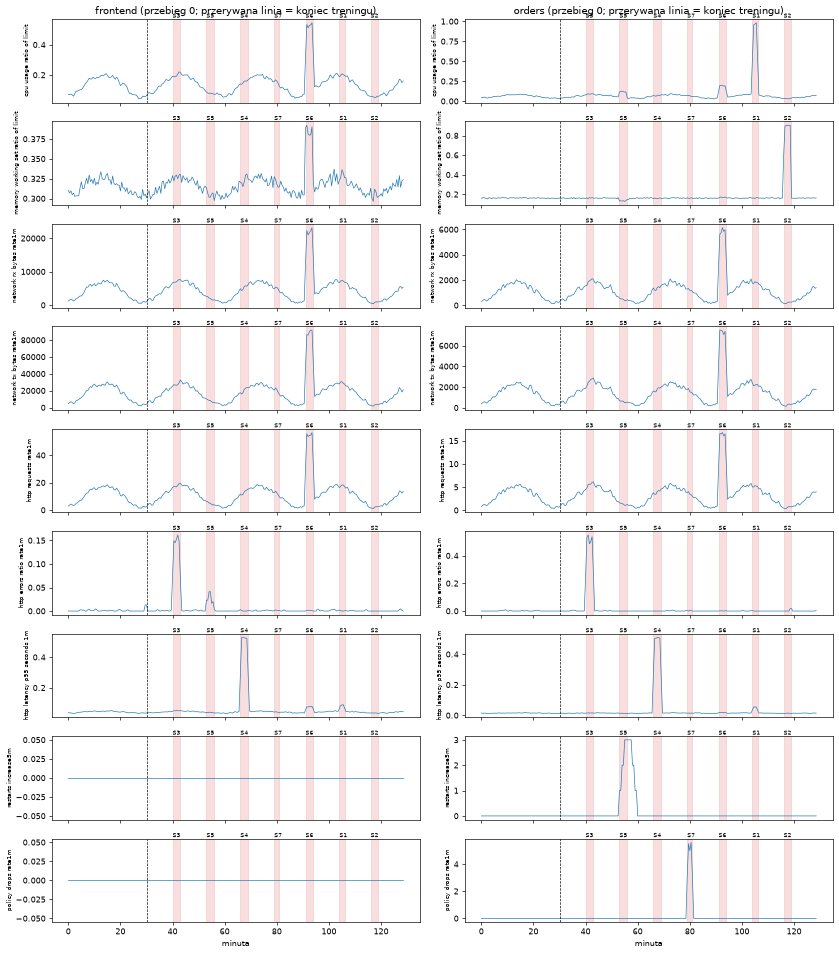

In [3]:
def shade(ax: plt.Axes, labels: pd.DataFrame) -> None:
    for row in labels.itertuples():
        ax.axvspan(
            row.start / STEPS_PER_MIN,
            row.end / STEPS_PER_MIN,
            color="tab:red",
            alpha=0.15,
        )
        ax.text(
            row.start / STEPS_PER_MIN,
            1.0,
            row.scenario,
            transform=ax.get_xaxis_transform(),
            fontsize=7,
            va="bottom",
        )
    ax.axvline(TRAIN_MINUTES, color="black", linestyle="--", linewidth=0.8)


fig, axes = plt.subplots(len(FEATURES), 2, figsize=(14, 16), sharex=True)
minutes = np.arange(len(example_data["orders"])) / STEPS_PER_MIN
for col, service in enumerate(SERVICES):
    for row, feature in enumerate(FEATURES):
        ax = axes[row, col]
        ax.plot(minutes, example_data[service][feature], linewidth=0.8)
        shade(ax, example_labels)
        ax.set_ylabel(feature.replace("_", " "), fontsize=7)
        if row == 0:
            ax.set_title(f"{service} (przebieg 0; przerywana linia = koniec treningu)")
axes[-1, 0].set_xlabel("minuta")
axes[-1, 1].set_xlabel("minuta")
fig.tight_layout()

## Detektory

Wszystkie trzy działają osobno dla każdej usługi i dają flagę anomalii w każdym kroku 30 s.

- **IsolationForest** — dokładnie potok z T23: `StandardScaler` + `IsolationForest(n_estimators=200, random_state=42)` uczony na 30 min rozgrzewki; wynik = −`score_samples`.
- **Kroczący z-score** — dla każdej cechy z = (x − średnia) / odchylenie z poprzednich 30 min (bez bieżącego punktu); wynik = max |z| po cechach. Odchylenie ma dolną granicę na cechę (`STD_FLOOR`), bo `restarts` i `policy_drops` są w ruchu normalnym stale zerowe, a z nieograniczonym mianownikiem pojedynczy błąd 5xx dawałby nieskończone |z|.
- **Stałe progi** — progi i `for` alertów regułowych z `docs/architektura.md` (HighCPU, HighMemory, HighErrorRate, HighLatency, PodRestarts, PolicyDeniedConnections).

Próg detektorów ML = percentyl wyników z okna treningowego (dane czyste). Porównujemy kilka percentyli.

In [4]:
STD_FLOOR = pd.Series(
    {
        "cpu_usage_ratio_of_limit": 0.02,
        "memory_working_set_ratio_of_limit": 0.02,
        "network_rx_bytes_rate1m": 200.0,
        "network_tx_bytes_rate1m": 500.0,
        "http_requests_rate1m": 0.5,
        "http_errors_ratio_rate1m": 0.01,
        "http_latency_p95_seconds_1m": 0.01,
        "restarts_increase5m": 0.5,
        "policy_drops_rate1m": 0.5,
    }
)
Z_MIN_HISTORY = 10  # pierwsze 5 min rozgrzewki nie ma jeszcze sensownej historii

RULES = {  # nazwa: (cecha, próg, for w minutach)
    "HighCPU": ("cpu_usage_ratio_of_limit", 0.8, 2),
    "HighMemory": ("memory_working_set_ratio_of_limit", 0.85, 2),
    "HighErrorRate": ("http_errors_ratio_rate1m", 0.05, 2),
    "HighLatency": ("http_latency_p95_seconds_1m", 0.3, 2),
    "PodRestarts": ("restarts_increase5m", 0, 0),
    "PolicyDeniedConnections": ("policy_drops_rate1m", 0, 1),
}
ML_FOR_MINUTES = 1  # AnomalyDetected


def isolation_forest_scores(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    model = make_pipeline(
        StandardScaler(), IsolationForest(n_estimators=200, random_state=42)
    )
    model.fit(df.iloc[:TRAIN_STEPS])
    scores = -model.score_samples(df)
    return scores, scores[:TRAIN_STEPS]


def rolling_z_scores(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    history = df.shift(1).rolling(TRAIN_STEPS, min_periods=Z_MIN_HISTORY)
    std = history.std().clip(lower=STD_FLOOR, axis=1)
    scores = ((df - history.mean()) / std).abs().max(axis=1).fillna(0).to_numpy()
    return scores, scores[Z_MIN_HISTORY:TRAIN_STEPS]


def firing(flags: np.ndarray, for_minutes: int) -> np.ndarray:
    """Stan alertu Prometheusa: warunek prawdziwy w for_minutes*2 + 1 kolejnych ewaluacjach."""
    run = np.zeros(len(flags), dtype=int)
    count = 0
    for i, flag in enumerate(flags):
        count = count + 1 if flag else 0
        run[i] = count
    return run > for_minutes * STEPS_PER_MIN


def rules_firing(df: pd.DataFrame) -> np.ndarray:
    states = [
        firing((df[feature] > threshold).to_numpy(), for_min)
        for feature, threshold, for_min in RULES.values()
    ]
    return np.logical_or.reduce(states)


def alert_starts(state: np.ndarray) -> np.ndarray:
    previous = np.concatenate([[False], state[:-1]])
    return np.flatnonzero(state & ~previous)

## Ewaluacja

`evaluate` zamienia stany alertów obu usług na wykrycia, opóźnienia i fałszywe alarmy według definicji T30. Alerty liczymy tylko po zakończeniu okna treningowego.

In [5]:
def evaluate(states: dict[str, np.ndarray], labels: pd.DataFrame) -> dict:
    n = len(next(iter(states.values())))
    windows = [
        (row.start - GRACE_BEFORE, row.end + GRACE_AFTER) for row in labels.itertuples()
    ]
    alerts = [
        (service, start)
        for service, state in states.items()
        for start in alert_starts(state)
        if start >= TRAIN_STEPS
    ]

    in_window = sum(any(lo <= start < hi for lo, hi in windows) for _, start in alerts)
    detections = {}
    for row in labels.itertuples():
        starts = [
            start
            for service, start in alerts
            if service == row.target and row.start <= start < row.end + GRACE_AFTER
        ]
        detections[row.scenario] = (
            (min(starts) - row.start) / STEPS_PER_MIN if starts else None
        )

    return {
        "alerts": len(alerts),
        "in_window": in_window,
        "false_alarms": len(alerts) - in_window,
        "hours": (n - TRAIN_STEPS) / (60 * STEPS_PER_MIN),
        "detections": detections,
    }


def summarize(results: list[dict]) -> dict:
    alerts = sum(r["alerts"] for r in results)
    precision = sum(r["in_window"] for r in results) / alerts if alerts else 0.0
    delays = [d for r in results for d in r["detections"].values() if d is not None]
    detected = [sum(d is not None for d in r["detections"].values()) for r in results]
    recall = np.mean(detected) / len(SCENARIOS)
    return {
        "wykryte (z 7)": np.mean(detected),
        "min wykrytych": min(detected),
        "recall": recall,
        "precision": precision,
        "F1": 2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0,
        "fałszywe alarmy / h": sum(r["false_alarms"] for r in results)
        / sum(r["hours"] for r in results),
        "mediana opóźnienia (min)": float(np.median(delays)) if delays else np.nan,
    }


SCORERS = {"IsolationForest": isolation_forest_scores, "z-score": rolling_z_scores}
PERCENTILES = [90, 95, 99, 99.5, 100]


def compare(runs: list) -> tuple[pd.DataFrame, dict, dict]:
    """Wszystkie detektory i progi na tych samych przebiegach."""
    # Wyniki ML liczymy raz na przebieg; zmienia się tylko próg.
    scores = {
        method: [
            {service: scorer(data[service]) for service in SERVICES} for data, _ in runs
        ]
        for method, scorer in SCORERS.items()
    }
    results = {}
    for method in SCORERS:
        for percentile in PERCENTILES:
            per_run = []
            for (_, labels), per_service in zip(runs, scores[method]):
                states = {
                    service: firing(
                        s > np.percentile(train, percentile), ML_FOR_MINUTES
                    )
                    for service, (s, train) in per_service.items()
                }
                per_run.append(evaluate(states, labels))
            results[(method, f"p{percentile}")] = per_run
    results[("stałe progi", "reguły")] = [
        evaluate({service: rules_firing(data[service]) for service in SERVICES}, labels)
        for data, labels in runs
    ]
    table = pd.DataFrame({key: summarize(r) for key, r in results.items()}).T
    table.index.names = ["detektor", "próg"]
    return table, results, scores


def per_scenario(results: dict) -> pd.DataFrame:
    chosen = {
        "IsolationForest p99.5 (T23)": results[("IsolationForest", "p99.5")],
        "IsolationForest p95": results[("IsolationForest", "p95")],
        "z-score p99.5": results[("z-score", "p99.5")],
        "z-score p95": results[("z-score", "p95")],
        "stałe progi": results[("stałe progi", "reguły")],
    }
    rate = pd.DataFrame(
        {
            name: [
                np.mean([r["detections"][s.id] is not None for r in runs])
                for s in SCENARIOS
            ]
            for name, runs in chosen.items()
        },
        index=[f"{s.id} {s.name}" for s in SCENARIOS],
    )
    delay = pd.DataFrame(
        {
            name: [
                np.median(
                    [
                        r["detections"][s.id]
                        for r in runs
                        if r["detections"][s.id] is not None
                    ]
                    or [np.nan]
                )
                for s in SCENARIOS
            ]
            for name, runs in chosen.items()
        },
        index=rate.index,
    )
    return pd.concat(
        {"odsetek wykryć": rate, "mediana opóźnienia (min)": delay}, axis=1
    )


RUNS = [simulate(seed) for seed in SEEDS]
comparison, RESULTS, SCORES = compare(RUNS)
comparison

wykryte (z 7)  min wykrytych  recall  precision  \
detektor        próg                                                      
IsolationForest p90              4.55            3.0   0.650      0.855   
                p95              3.60            1.0   0.514      0.929   
                p99              1.75            1.0   0.250      0.942   
                p99.5            1.60            1.0   0.229      0.984   
                p100             1.45            0.0   0.207      1.000   
z-score         p90              7.00            7.0   1.000      1.000   
                p95              7.00            7.0   1.000      1.000   
                p99              6.95            6.0   0.993      1.000   
                p99.5            6.95            6.0   0.993      1.000   
                p100             6.90            5.0   0.986      1.000   
stałe progi     reguły           5.00            5.0   0.714      1.000   

                           F1  fałszywe alarmy / h  mediana opóźnienia (min)  
detektor        próg                                                          
IsolationForest p90     0.738                1.061                       1.0  
                p95     0.662                0.333                       1.0  
                p99     0.395                0.121                       1.0  
                p99.5   0.371                0.030                       1.0  
                p100    0.343                0.000                       1.0  
z-score         p90     1.000                0.000                       1.0  
                p95     1.000                0.000                       1.0  
                p99     0.996                0.000                       1.0  
                p99.5   0.996                0.000                       1.0  
                p100    0.993                0.000                       1.0  
stałe progi     reguły  0.833                0.000                       2.0

### Wykrycia według scenariusza

Odsetek z 20 przebiegów, w których alert usługi docelowej zaczął się w [start, end + 5 min]. Detektory ML przy progu p99,5 (domyślny w T23) i p95.

In [6]:
per_scenario(RESULTS)

odsetek wykryć                                    \
           IsolationForest p99.5 (T23) IsolationForest p95 z-score p99.5   
S1 cpu                            0.20                0.65          1.00   
S2 memory                         0.05                0.15          1.00   
S3 errors                         0.30                0.90          1.00   
S4 latency                        0.10                0.25          1.00   
S5 crash                          0.10                0.60          0.95   
S6 spike                          0.85                1.00          1.00   
S7 scan                           0.00                0.05          1.00   

                                      mediana opóźnienia (min)  \
           z-score p95 stałe progi IsolationForest p99.5 (T23)   
S1 cpu             1.0         0.0                        1.00   
S2 memory          1.0         1.0                        1.00   
S3 errors          1.0         1.0                        1.00   
S4 latency         1.0         1.0                        4.25   
S5 crash           1.0         1.0                        1.00   
S6 spike           1.0         0.0                        1.00   
S7 scan            1.0         1.0                         NaN   

                                                                      
           IsolationForest p95 z-score p99.5 z-score p95 stałe progi  
S1 cpu                     1.0           1.0         1.0         NaN  
S2 memory                  1.0           1.0         1.0         2.5  
S3 errors                  1.0           1.0         1.0         2.0  
S4 latency                 2.5           1.0         1.0         2.5  
S5 crash                   1.5           2.0         1.5         0.0  
S6 spike                   1.0           1.0         1.0         NaN  
S7 scan                    6.5           1.0         1.0         1.0

### Trudniejszy ruch bazowy

Ten sam eksperyment z dwukrotnie większym szumem i zakłóceniami w 2% kroków każdej usługi (jednorazowo: +0,1 CPU, +150 ms p95, 3% błędów, np. GC albo zimna ścieżka). Takie pojedyncze piki nie powinny dawać alertu, bo `for: 1m` wymaga 3 kolejnych flag.

In [7]:
HARD_RUNS = [simulate(seed, noise=2.0, glitch_rate=0.02) for seed in SEEDS]
hard_comparison, HARD_RESULTS, HARD_SCORES = compare(HARD_RUNS)
hard_comparison

wykryte (z 7)  min wykrytych  recall  precision  \
detektor        próg                                                      
IsolationForest p90              4.40            1.0   0.629      0.877   
                p95              2.35            1.0   0.336      0.970   
                p99              0.45            0.0   0.064      1.000   
                p99.5            0.40            0.0   0.057      1.000   
                p100             0.40            0.0   0.057      1.000   
z-score         p90              7.00            7.0   1.000      1.000   
                p95              6.90            6.0   0.986      1.000   
                p99              3.55            0.0   0.507      1.000   
                p99.5            2.15            0.0   0.307      1.000   
                p100             1.35            0.0   0.193      1.000   
stałe progi     reguły           5.00            5.0   0.714      1.000   

                           F1  fałszywe alarmy / h  mediana opóźnienia (min)  
detektor        próg                                                          
IsolationForest p90     0.732                0.758                       1.0  
                p95     0.499                0.091                       1.0  
                p99     0.121                0.000                       1.0  
                p99.5   0.108                0.000                       1.0  
                p100    0.108                0.000                       1.0  
z-score         p90     1.000                0.000                       1.0  
                p95     0.993                0.000                       1.0  
                p99     0.673                0.000                       1.0  
                p99.5   0.470                0.000                       1.0  
                p100    0.323                0.000                       1.0  
stałe progi     reguły  0.833                0.000                       2.0

In [8]:
per_scenario(HARD_RESULTS)

odsetek wykryć                                    \
           IsolationForest p99.5 (T23) IsolationForest p95 z-score p99.5   
S1 cpu                            0.00                0.35          0.30   
S2 memory                         0.00                0.05          0.20   
S3 errors                         0.05                0.45          0.65   
S4 latency                        0.00                0.40          0.35   
S5 crash                          0.00                0.05          0.10   
S6 spike                          0.35                1.00          0.40   
S7 scan                           0.00                0.05          0.15   

                                      mediana opóźnienia (min)  \
           z-score p95 stałe progi IsolationForest p99.5 (T23)   
S1 cpu             1.0         0.0                         NaN   
S2 memory          1.0         1.0                         NaN   
S3 errors          1.0         1.0                         2.0   
S4 latency         1.0         1.0                         NaN   
S5 crash           0.9         1.0                         NaN   
S6 spike           1.0         0.0                         1.0   
S7 scan            1.0         1.0                         NaN   

                                                                      
           IsolationForest p95 z-score p99.5 z-score p95 stałe progi  
S1 cpu                     1.0           1.0         1.0         NaN  
S2 memory                  4.5           1.0         1.0         2.5  
S3 errors                  1.0           1.0         1.0         2.0  
S4 latency                 1.0           1.0         1.0         2.5  
S5 crash                   1.5           2.5         2.0         0.0  
S6 spike                   1.0           1.0         1.0         NaN  
S7 scan                    6.0           1.0         1.0         1.0

### Progi z-score w praktyce

Wartości progu (max |z|) z rozgrzewki w 20 przebiegach, osobno dla usług. Rozgrzewka ma ok. 50 wyników, więc p99,5 to praktycznie maksimum: jeden pik w rozgrzewce podnosi próg do poziomu, którego zwykła anomalia nie przekracza. p95 pomija 2–3 najwyższe wyniki.

In [9]:
def threshold_spread(scores: dict, percentile: float) -> pd.DataFrame:
    return pd.DataFrame(
        {
            service: pd.Series(
                [
                    np.percentile(run[service][1], percentile)
                    for run in scores["z-score"]
                ]
            ).describe()[["min", "50%", "max"]]
            for service in SERVICES
        }
    ).T


pd.concat(
    {
        (baseline, f"p{p}"): threshold_spread(scores, p)
        for baseline, scores in {"bazowy": SCORES, "trudniejszy": HARD_SCORES}.items()
        for p in (95, 99.5)
    }
)

min    50%    max
bazowy      p95   frontend  2.082  2.521  3.738
                  orders    1.996  2.449  3.145
            p99.5 frontend  2.203  2.742  4.222
                  orders    2.207  2.710  5.676
trudniejszy p95   frontend  2.403  2.980  4.977
                  orders    2.447  3.082  4.647
            p99.5 frontend  2.852  6.490  8.147
                  orders    3.215  6.827  7.328

### Dlaczego IsolationForest gubi część scenariuszy

IsolationForest dzieli przestrzeń tylko w zakresie wartości widzianych w treningu. Wynikają z tego dwa ograniczenia:

1. **Cecha stała w rozgrzewce jest niewidoczna.** `restarts_increase5m` i `policy_drops_rate1m` są w ruchu normalnym równe 0, nie dają żadnego podziału, więc ich zmiana nie zmienia wyniku (S5, S7).
2. **Nasycenie poza zakresem.** Punkt poza zakresem treningu w jednej cesze jest izolowany tak samo szybko jak najbardziej skrajny punkt treningowy w tej cesze. Pamięć 0,9 limitu ma ten sam wynik co pamięć tuż nad maksimum z treningu, a próg p99,5 leży właśnie na wynikach skrajnych punktów treningowych. Anomalia w 1 z 9 cech ledwo go przekracza (S1, S2, S4).

In [10]:
data0 = RUNS[0][0]["orders"]
train0 = data0.iloc[:TRAIN_STEPS]
model = make_pipeline(
    StandardScaler(), IsolationForest(n_estimators=200, random_state=42)
).fit(train0)
point = train0.iloc[
    [
        train0["memory_working_set_ratio_of_limit"]
        .sub(train0["memory_working_set_ratio_of_limit"].median())
        .abs()
        .argmin()
    ]
]
memory_max = train0["memory_working_set_ratio_of_limit"].max()


def if_score(**changes: float) -> float:
    return float(-model.score_samples(point.assign(**changes))[0])


pd.Series(
    {
        "punkt typowy z rozgrzewki": if_score(),
        "ten sam punkt + policy_drops=6, restarts=3": if_score(
            policy_drops_rate1m=6.0, restarts_increase5m=3.0
        ),
        f"ten sam punkt, pamięć {memory_max + 0.01:.2f} (tuż nad max)": if_score(
            memory_working_set_ratio_of_limit=memory_max + 0.01
        ),
        "ten sam punkt, pamięć 0.90 (S2)": if_score(
            memory_working_set_ratio_of_limit=0.9
        ),
        "próg p99.5": float(np.percentile(-model.score_samples(train0), 99.5)),
    },
    name="wynik IsolationForest (orders, przebieg 0)",
)

punkt typowy z rozgrzewki                     0.526
ten sam punkt + policy_drops=6, restarts=3    0.526
ten sam punkt, pamięć 0.18 (tuż nad max)      0.571
ten sam punkt, pamięć 0.90 (S2)               0.571
próg p99.5                                    0.559
Name: wynik IsolationForest (orders, przebieg 0), dtype: float64

### Wyniki w czasie (przebieg 0, `orders`)

Wynik każdego detektora ML z progami p95 i p99,5; czerwone pasy to okna scenariuszy.

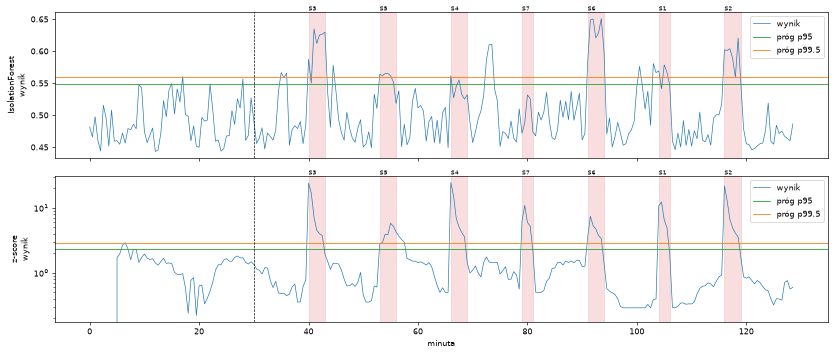

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, method in zip(axes, SCORERS):
    scores, train_scores = SCORES[method][0]["orders"]
    ax.plot(minutes, scores, linewidth=0.8, label="wynik")
    ax.axhline(
        np.percentile(train_scores, 95),
        color="tab:green",
        linewidth=1,
        label="próg p95",
    )
    ax.axhline(
        np.percentile(train_scores, 99.5),
        color="tab:orange",
        linewidth=1,
        label="próg p99.5",
    )
    shade(ax, RUNS[0][1])
    ax.set_ylabel(f"{method}\nwynik")
    ax.legend(loc="upper right")
axes[0].set_yscale("linear")
axes[1].set_yscale("log")
axes[-1].set_xlabel("minuta")
fig.tight_layout()

### Odporność na powolny dryf

Model uczony raz na 30 min może później zobaczyć wolną, nieszkodliwą zmianę, np. pamięć `orders` rosnącą razem z magazynem zamówień do `MAX_ORDERS`. Sprawdzamy fałszywe alarmy na 4 h czystego ruchu (bez scenariuszy), w którym po treningu pamięć `orders` rośnie o 0,02 limitu na godzinę.

In [12]:
drift_rows = {}
for drift in (0.0, 0.02):
    clean_runs = [
        simulate(seed, scenarios=(), extra_minutes=240, memory_drift_per_hour=drift)
        for seed in SEEDS
    ]
    for method, scorer in SCORERS.items():
        for percentile in (95, 99.5):
            false_alarms, hours = 0, 0.0
            for data, _ in clean_runs:
                for df in data.values():
                    scores, train_scores = scorer(df)
                    state = firing(
                        scores > np.percentile(train_scores, percentile), ML_FOR_MINUTES
                    )
                    false_alarms += len(
                        [s for s in alert_starts(state) if s >= TRAIN_STEPS]
                    )
                hours += (len(df) - TRAIN_STEPS) / (60 * STEPS_PER_MIN)
            drift_rows[(f"{method} p{percentile}", f"dryf {drift}/h")] = (
                false_alarms / hours
            )
pd.Series(drift_rows, name="fałszywe alarmy / h na czystym ruchu").unstack()

,dryf 0.0/h,dryf 0.02/h
IsolationForest p95,0.816,2.220
IsolationForest p99.5,0.072,0.432
z-score p95,0.012,0.012
z-score p99.5,0.000,0.000


## Wnioski

Wnioski i wybór metody są w [`docs/detekcja.md`](../../docs/detekcja.md).